In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the dataset
df=pd.read_csv('13-car_evaluation.csv')

In [2]:
df.head()

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [4]:
df.shape

(1727, 7)

In [5]:
col_names=["buying","maint","doors","persons","lug_boot","safety","class"]
df.columns=col_names
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   object
 3   persons   1727 non-null   object
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [10]:
for col in df.columns:
    print(df[col].value_counts())

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
doors
3        432
4        432
5more    432
2        431
Name: count, dtype: int64
persons
4       576
more    576
2       575
Name: count, dtype: int64
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64
safety
med     576
high    576
low     575
Name: count, dtype: int64
class
unacc    1209
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [11]:
df.isnull().sum()

buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

In [12]:
df["doors"].unique()

array(['2', '3', '4', '5more'], dtype=object)

In [13]:
df["doors"]=df["doors"].replace("5more",5)
df["doors"]=df["doors"].astype(int)

In [14]:
df["doors"].unique()

array([2, 3, 4, 5])

In [ ]:
df["persons"].unique()

array(['2', '4', 'more'], dtype=object)

In [16]:
df["persons"]=df["persons"].replace("more",5)
df["persons"]=df["persons"].astype(int)


In [17]:
df["persons"].unique()


array([2, 4, 5])

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   int32 
 3   persons   1727 non-null   int32 
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: int32(2), object(5)
memory usage: 81.1+ KB


<Axes: xlabel='buying', ylabel='maint'>

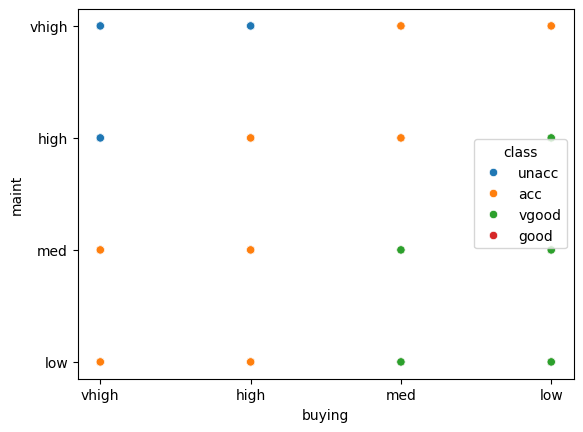

In [19]:
sns.scatterplot(x="buying",y="maint",hue="class",data=df)

<Axes: xlabel='lug_boot', ylabel='safety'>

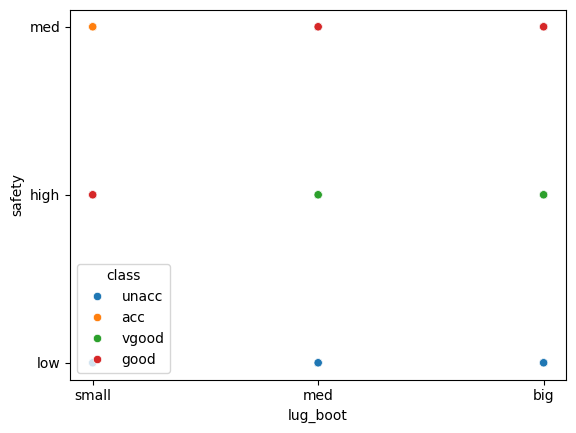

In [20]:
sns.scatterplot(x="lug_boot",y="safety",hue="class",data=df)


In [21]:
X=df.drop("class",axis=1)
y=df["class"]
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=15)

In [23]:
# ordinal encoding yapacağız çünkü kategorik değişkenlerimiz var ve bu değişkenlerin sıralaması var. Örneğin "buying" değişkeninde "low" < "med" < "high" < "vhigh" şeklinde bir sıralama var. Bu yüzden ordinal encoding kullanacağız.
from sklearn.preprocessing import OrdinalEncoder
ordinal_encoder=OrdinalEncoder(categories=[
    ["low","med","high","vhigh"], # buying
    ["low","med","high","vhigh"], # maint
    ["small","med","big"], # lug_boot
    ["low","med","high"]   # safety
])
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
categorical_cols=["buying","maint","lug_boot","safety"]
numeric_cols=["doors","persons"]

preprocessor=ColumnTransformer(transformers=[
    ("ordinal_encoder_ismi_biz_seçtik",ordinal_encoder,categorical_cols) #bunu one hot olarak da yapabilirdik ama bu değişkenlerin sıralaması olduğu için ordinal encoding kullanacağız.
], remainder="passthrough")
X_train_transformed=preprocessor.fit_transform(X_train)
X_test_transformed=preprocessor.transform(X_test)


In [45]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score
decision_tree_classifier=DecisionTreeClassifier(random_state=0,max_depth=None,criterion="entropy",max_features=None,splitter="best")
decision_tree_classifier.fit(X_train_transformed,y_train)
y_pred=decision_tree_classifier.predict(X_test_transformed)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9791666666666666
Confusion Matrix:
[[ 91   0   1   1]
 [  3  16   0   0]
 [  4   0 301   0]
 [  0   0   0  15]]
Classification Report:
              precision    recall  f1-score   support

         acc       0.93      0.98      0.95        93
        good       1.00      0.84      0.91        19
       unacc       1.00      0.99      0.99       305
       vgood       0.94      1.00      0.97        15

    accuracy                           0.98       432
   macro avg       0.97      0.95      0.96       432
weighted avg       0.98      0.98      0.98       432



[Text(0.6098214285714286, 0.9545454545454546, 'ordinal_encoder_ismi_biz_seçtik__safety <= 0.5\nentropy = 1.209\nsamples = 1295\nvalue = [291, 50, 904, 50]\nclass = unacc'),
 Text(0.5955357142857143, 0.8636363636363636, 'entropy = 0.0\nsamples = 436\nvalue = [0, 0, 436, 0]\nclass = unacc'),
 Text(0.6026785714285714, 0.9090909090909092, 'True  '),
 Text(0.6241071428571429, 0.8636363636363636, 'remainder__persons <= 3.0\nentropy = 1.484\nsamples = 859\nvalue = [291.0, 50.0, 468.0, 50.0]\nclass = unacc'),
 Text(0.6169642857142857, 0.9090909090909092, '  False'),
 Text(0.6098214285714286, 0.7727272727272727, 'entropy = 0.0\nsamples = 281\nvalue = [0, 0, 281, 0]\nclass = unacc'),
 Text(0.6383928571428571, 0.7727272727272727, 'ordinal_encoder_ismi_biz_seçtik__buying <= 1.5\nentropy = 1.636\nsamples = 578\nvalue = [291.0, 50.0, 187.0, 50.0]\nclass = acc'),
 Text(0.40535714285714286, 0.6818181818181818, 'ordinal_encoder_ismi_biz_seçtik__maint <= 1.5\nentropy = 1.725\nsamples = 298\nvalue = [160

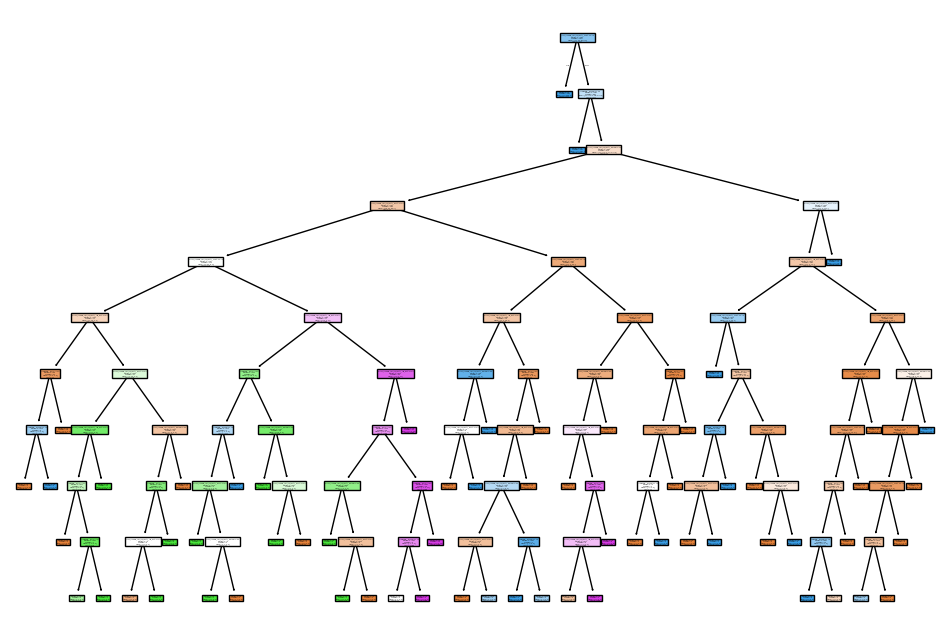

In [39]:
plt.figure(figsize=(12,8))
from sklearn.tree import plot_tree
plot_tree(decision_tree_classifier, filled=True, feature_names=preprocessor.get_feature_names_out(), class_names=decision_tree_classifier.classes_)

In [41]:
# hyperparameter tuning
param={
    "criterion": ["gini", "entropy", "log_loss"],
    "splitter": ["best", "random"],
    "max_depth": [5, 10, 15, 20, None],
    "max_features": [None, "sqrt", "log2"]
    
}

In [42]:
from sklearn.model_selection import GridSearchCV
grid=GridSearchCV(estimator= decision_tree_classifier, param_grid=param, cv=5,scoring="accuracy")
import warnings
warnings.filterwarnings("ignore")
grid.fit(X_train_transformed,y_train)

GridSearchCV(cv=5,
             estimator=DecisionTreeClassifier(criterion='entropy', max_depth=10,
                                              random_state=0),
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [5, 10, 15, 20, None],
                         'max_features': [None, 'sqrt', 'log2'],
                         'splitter': ['best', 'random']},
             scoring='accuracy')

In [43]:
print("Best Parameters:", grid.best_params_)


Best Parameters: {'criterion': 'gini', 'max_depth': 15, 'max_features': None, 'splitter': 'best'}


In [44]:
y_pred_grid=grid.predict(X_test_transformed)
print("Accuracy:", accuracy_score(y_test, y_pred_grid))
print("Best Cross-Validation Score:", grid.best_score_)


Accuracy: 0.9837962962962963
Best Cross-Validation Score: 0.9722007722007723
